<a href="https://colab.research.google.com/github/LuisGomes25/datasync-Projeto-CRISP-DM-abandono/blob/main/notebooks/04_avaliacao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os                                                        # funções do sistema: pastas e caminhos

REPO = "datasync-Projeto-CRISP-DM-abandono"                       # nome da pasta que o clone vai criar
URL = f"https://github.com/LuisGomes25/{REPO}.git"                # endereço público do repositório

if not os.path.exists(REPO) and os.path.basename(os.getcwd()) != REPO:   # só clona se ainda não clonou
    !git clone -q {URL}                                           # copia o repositório para o Colab (-q = sem barulho)

if os.path.basename(os.getcwd()) != REPO:                         # só entra na pasta se ainda não estiver nela
    os.chdir(REPO)                                                # muda a pasta de trabalho para o repositório

!pip install -q shap==0.54.1                                      # instala o SHAP na versão do requirements.txt

os.makedirs("resultados/sprint6", exist_ok=True)                  # cria a pasta de saída (não dá erro se já existir)
print("Pasta atual:", os.getcwd())                                # confirma onde estamos

Pasta atual: /content/datasync-Projeto-CRISP-DM-abandono


In [ ]:
import numpy as np                                                # cálculos numéricos
import pandas as pd                                               # tabelas

SEED = 42                                                         # semente: garante o mesmo resultado em toda execução
ETAPAS = ["ensino_medio", "anos_finais", "anos_iniciais"]         # as três etapas, na ordem da Sprint 5

MELHOR_MODELO = {                                                 # vencedores da Sprint 5 (maior PR-AUC)
    "ensino_medio":  "Random_Forest",
    "anos_finais":   "Hist_Gradient_Boosting",
    "anos_iniciais": "Hist_Gradient_Boosting",
}

NUM_BASE = [                                                      # variáveis numéricas do cenário completo da Sprint 5
    "tdi_distorcao", "atu_alunos_turma", "had_horas_aula",
    "dsu_doc_superior", "afd_formacao_adequada", "ied_esforco_alto",
    "icg_complexidade", "ird_regularidade", "inse_media",
    "flag_inse_ausente", "log_matriculas", "pct_noturno",
    "pct_integral", "pct_transporte_publico", "alunos_por_docente",
    "indice_infra", "flag_sem_turma_etapa",
]
CAT_BASE = ["SG_UF", "NO_CATEGORIA", "NO_DEPENDENCIA"]            # variáveis de texto: UF, urbana/rural, rede

df = pd.read_csv(
    "dados/tabela_analitica.csv",                                 # caminho relativo: funciona para qualquer pessoa
    encoding="utf-8-sig",                                         # remove um caractere invisível do início do arquivo
    dtype={"codigo_escola": str, "CO_MUNICIPIO": str},            # códigos como texto (não perdem zeros nem viram número)
    low_memory=False,                                             # lê o arquivo inteiro de uma vez para acertar os tipos
)

assert df.shape == (136713, 27), df.shape                         # trava: para tudo se a base não for a esperada
faltando = [c for c in NUM_BASE + CAT_BASE if c not in df.columns]   # lista colunas que deveriam existir e não existem
assert not faltando, faltando                                     # trava: para tudo se faltar alguma

def criar_alvo(serie, percentil=80):                              # mesma regra da Sprint 5
    limite = float(serie.quantile(percentil / 100))               # valor da taxa no percentil pedido
    if limite == 0.0:                                             # nos Anos Iniciais o P80 é zero...
        return (serie > 0).astype(int), limite                    # ...então "alto" = qualquer abandono
    return (serie >= limite).astype(int), limite                  # demais etapas: taxa no limite ou acima

for etapa in ETAPAS:                                              # confere cada etapa
    sub = df[df["etapa"] == etapa]                                # separa as linhas da etapa
    y, lim = criar_alvo(sub["taxa_abandono"])                     # cria o alvo
    print(f"{etapa:15s} n={len(sub):>6,}  limite={lim:.2f}  alto={y.mean()*100:.2f}%")

ensino_medio    n=21,229  limite=4.40  alto=20.03%
anos_finais     n=44,803  limite=1.80  alto=20.12%
anos_iniciais   n=70,681  limite=0.00  alto=15.28%


In [ ]:
from sklearn.compose import ColumnTransformer                     # aplica tratamentos diferentes por tipo de coluna
from sklearn.pipeline import Pipeline                             # encadeia etapas: tratar dados → modelo
from sklearn.impute import SimpleImputer                          # preenche valores vazios
from sklearn.preprocessing import StandardScaler, OneHotEncoder   # padroniza números / transforma texto em colunas 0-1
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier   # os dois modelos vencedores
from sklearn.model_selection import StratifiedGroupKFold          # divide os dados mantendo municípios inteiros juntos
from sklearn.metrics import average_precision_score, roc_auc_score   # métricas da Sprint 5 (PR-AUC e ROC-AUC)

def montar_modelo(nome):                                          # monta o mesmo pipeline da Sprint 5
    num = Pipeline([
        ("imputacao", SimpleImputer(strategy="median")),          # vazio numérico → mediana (calculada só no treino)
        ("escala", StandardScaler()),                             # deixa as variáveis na mesma escala
    ])
    cat = Pipeline([
        ("imputacao", SimpleImputer(strategy="most_frequent")),   # vazio de texto → valor mais comum
        ("onehot", OneHotEncoder(handle_unknown="ignore",         # "SP" vira uma coluna 0/1; UF nova é ignorada
                                 sparse_output=False)),
    ])
    prep = ColumnTransformer([("num", num, NUM_BASE),             # aplica o tratamento numérico às numéricas
                              ("cat", cat, CAT_BASE)])            # e o de texto às categóricas

    if nome == "Random_Forest":                                   # mesmos parâmetros da Sprint 5
        clf = RandomForestClassifier(n_estimators=250, max_depth=14, min_samples_leaf=8,
                                     class_weight="balanced", random_state=SEED, n_jobs=-1)
    else:
        clf = HistGradientBoostingClassifier(max_iter=250, max_depth=6, learning_rate=0.05,
                                             min_samples_leaf=20, class_weight="balanced",
                                             random_state=SEED)
    return Pipeline([("prep", prep), ("clf", clf)])               # tratamento + modelo num objeto só

dados, modelos, oof = {}, {}, {}                                  # guardam, por etapa: dados, modelo final e probabilidades

for etapa in ETAPAS:
    sub = (df[df["etapa"] == etapa]                               # linhas da etapa
           .dropna(subset=["taxa_abandono", "CO_MUNICIPIO"])      # exige taxa e município (igual à Sprint 5)
           .reset_index(drop=True))                               # renumera as linhas de 0 a n
    y, _ = criar_alvo(sub["taxa_abandono"])                       # alvo P80
    y = y.values                                                  # vira array simples
    X = sub[NUM_BASE + CAT_BASE]                                  # só as variáveis permitidas (sem a coluna-gabarito)
    grupos = sub["CO_MUNICIPIO"].values                           # município de cada escola

    prob = np.zeros(len(sub))                                     # espaço para a probabilidade de cada escola
    for treino, teste in StratifiedGroupKFold(n_splits=5).split(X, y, grupos):   # 5 rodadas
        m = montar_modelo(MELHOR_MODELO[etapa])                   # modelo novo a cada rodada
        m.fit(X.iloc[treino], y[treino])                          # aprende com 4/5 dos municípios
        prob[teste] = m.predict_proba(X.iloc[teste])[:, 1]        # dá nota ao 1/5 que ele nunca viu

    final = montar_modelo(MELHOR_MODELO[etapa])                   # modelo final...
    final.fit(X, y)                                               # ...treinado com tudo (será usado no SHAP)

    dados[etapa], modelos[etapa], oof[etapa] = (sub, X, y), final, prob
    print(f"{etapa:15s} PR-AUC={average_precision_score(y, prob):.4f}  "
          f"ROC-AUC={roc_auc_score(y, prob):.4f}")

ensino_medio    PR-AUC=0.5172  ROC-AUC=0.8265
anos_finais     PR-AUC=0.5159  ROC-AUC=0.8210
anos_iniciais   PR-AUC=0.4675  ROC-AUC=0.8133


In [4]:
linhas = []                                                       # cada linha = uma etapa × um tamanho de lista

for etapa in ETAPAS:
    sub, X, y = dados[etapa]                                      # dados da etapa (célula 3)
    ordem = np.argsort(-oof[etapa])                               # posições das escolas da MAIOR para a menor probabilidade
    total_alto = y.sum()                                          # quantas escolas de alto abandono existem na etapa

    for k in [0.05, 0.10, 0.20]:                                  # capacidade da equipe: 5%, 10% ou 20% das escolas
        n_top = int(round(len(y) * k))                            # quantas escolas cabem na lista
        top = y[ordem[:n_top]]                                    # alvo real (0/1) das escolas do topo da lista
        linhas.append({
            "etapa": etapa,
            "k_pct": int(k * 100),                                # tamanho da lista em %
            "escolas_na_lista": n_top,
            "acertos": int(top.sum()),                            # quantas da lista são de alto abandono
            "precisao": round(top.mean(), 3),                     # acertos ÷ tamanho da lista
            "recall": round(top.sum() / total_alto, 3),           # acertos ÷ total de escolas de alto abandono
            "acaso": round(y.mean(), 3),                          # precisão se a lista fosse sorteada
            "vezes_melhor_que_acaso": round(top.mean() / y.mean(), 1),
        })

recall_k = pd.DataFrame(linhas)                                   # junta tudo numa tabela
recall_k.to_csv("resultados/sprint6/01_recall_at_k.csv", index=False, encoding="utf-8-sig")   # salva para o relatório
recall_k

,etapa,k_pct,escolas_na_lista,acertos,precisao,recall,acaso,vezes_melhor_que_acaso
0,ensino_medio,5,1061,685,0.646,0.161,0.200,3.2
1,ensino_medio,10,2123,1261,0.594,0.297,0.200,3.0
2,ensino_medio,20,4246,2228,0.525,0.524,0.200,2.6
3,anos_finais,5,2240,1456,0.650,0.162,0.201,3.2
4,anos_finais,10,4480,2644,0.590,0.293,0.201,2.9
5,anos_finais,20,8961,4676,0.522,0.519,0.201,2.6
6,anos_iniciais,5,3534,2202,0.623,0.204,0.153,4.1
7,anos_iniciais,10,7068,3767,0.533,0.349,0.153,3.5
8,anos_iniciais,20,14136,5996,0.424,0.555,0.153,2.8


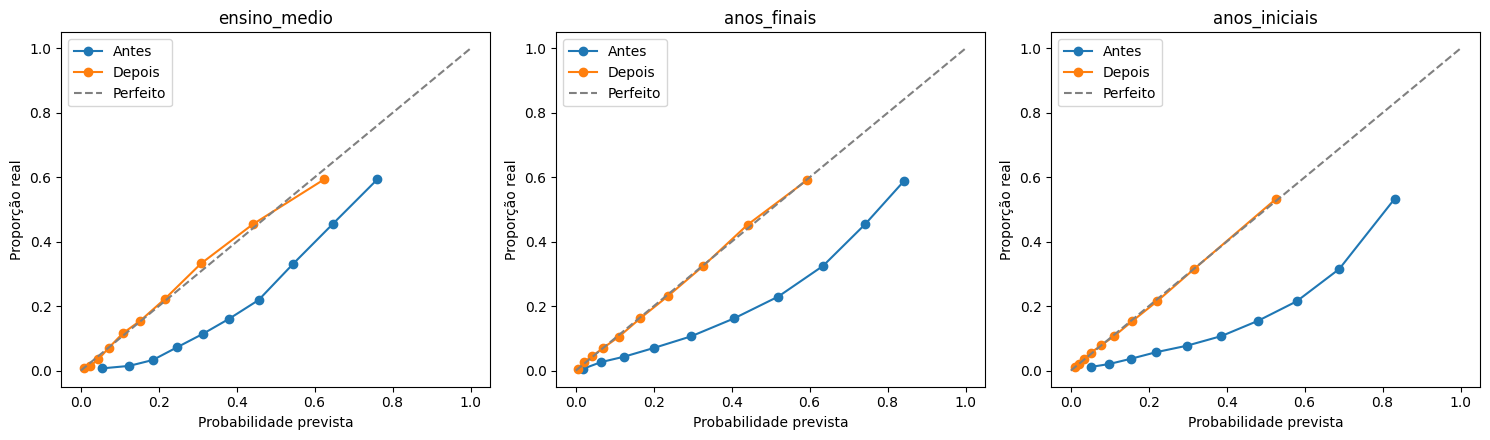

,etapa,prevalencia_real,prob_media_antes,prob_media_depois,brier_antes,brier_depois,precisao_top10_antes,precisao_top10_depois
0,ensino_medio,0.200,0.372,0.200,0.1556,0.1235,0.594,0.594
1,anos_finais,0.201,0.385,0.201,0.1696,0.1247,0.590,0.591
2,anos_iniciais,0.153,0.379,0.153,0.1682,0.1037,0.533,0.532


In [5]:
import matplotlib.pyplot as plt                                   # gráficos
from sklearn.linear_model import LogisticRegression               # usada como "régua" para corrigir as probabilidades
from sklearn.metrics import brier_score_loss                      # erro médio das probabilidades (quanto menor, melhor)
from sklearn.calibration import calibration_curve                 # compara probabilidade prevista × proporção real

def logit(p):                                                     # transforma probabilidade (0 a 1) numa escala sem limites
    p = np.clip(p, 1e-6, 1 - 1e-6)                                # evita 0 e 1 exatos (dariam infinito)
    return np.log(p / (1 - p)).reshape(-1, 1)                     # fórmula do logit, no formato de coluna

prob_cal, calibradores, linhas = {}, {}, []                       # probabilidades corrigidas, réguas finais e tabela
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))                # 3 gráficos lado a lado, um por etapa

for i, etapa in enumerate(ETAPAS):
    sub, X, y = dados[etapa]                                      # dados da etapa
    p = oof[etapa]                                                # probabilidades "honestas" da célula 3
    grupos = sub["CO_MUNICIPIO"].values                           # municípios

    p_cal = np.zeros(len(p))                                      # espaço para as probabilidades corrigidas
    for treino, teste in StratifiedGroupKFold(n_splits=5).split(X, y, grupos):
        regua = LogisticRegression()                              # régua nova a cada rodada
        regua.fit(logit(p[treino]), y[treino])                    # aprende "quanto encolher" em 4/5 dos municípios
        p_cal[teste] = regua.predict_proba(logit(p[teste]))[:, 1] # aplica no 1/5 restante

    calibradores[etapa] = LogisticRegression().fit(logit(p), y)   # régua final (para usar com o modelo final)
    prob_cal[etapa] = p_cal

    n = int(round(len(y) * 0.10))                                 # tamanho da lista dos 10%
    linhas.append({
        "etapa": etapa,
        "prevalencia_real": round(y.mean(), 3),                   # % real de alto abandono
        "prob_media_antes": round(p.mean(), 3),                   # média prevista sem correção
        "prob_media_depois": round(p_cal.mean(), 3),              # média prevista com correção
        "brier_antes": round(brier_score_loss(y, p), 4),
        "brier_depois": round(brier_score_loss(y, p_cal), 4),
        "precisao_top10_antes": round(y[np.argsort(-p)[:n]].mean(), 3),       # prova de que a lista
        "precisao_top10_depois": round(y[np.argsort(-p_cal)[:n]].mean(), 3),  # quase não muda
    })

    for nome, pp in [("Antes", p), ("Depois", p_cal)]:            # desenha as duas curvas
        real, previsto = calibration_curve(y, pp, n_bins=10, strategy="quantile")   # 10 faixas de mesmo tamanho
        eixos[i].plot(previsto, real, marker="o", label=nome)
    eixos[i].plot([0, 1], [0, 1], "--", color="gray", label="Perfeito")   # diagonal = calibração perfeita
    eixos[i].set_title(etapa)
    eixos[i].set_xlabel("Probabilidade prevista")
    eixos[i].set_ylabel("Proporção real")
    eixos[i].legend()

plt.tight_layout()
plt.savefig("resultados/sprint6/02_calibracao.png", dpi=300, bbox_inches="tight")   # salva para o relatório
plt.show()

calibracao = pd.DataFrame(linhas)
calibracao.to_csv("resultados/sprint6/02_calibracao.csv", index=False, encoding="utf-8-sig")
calibracao

/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


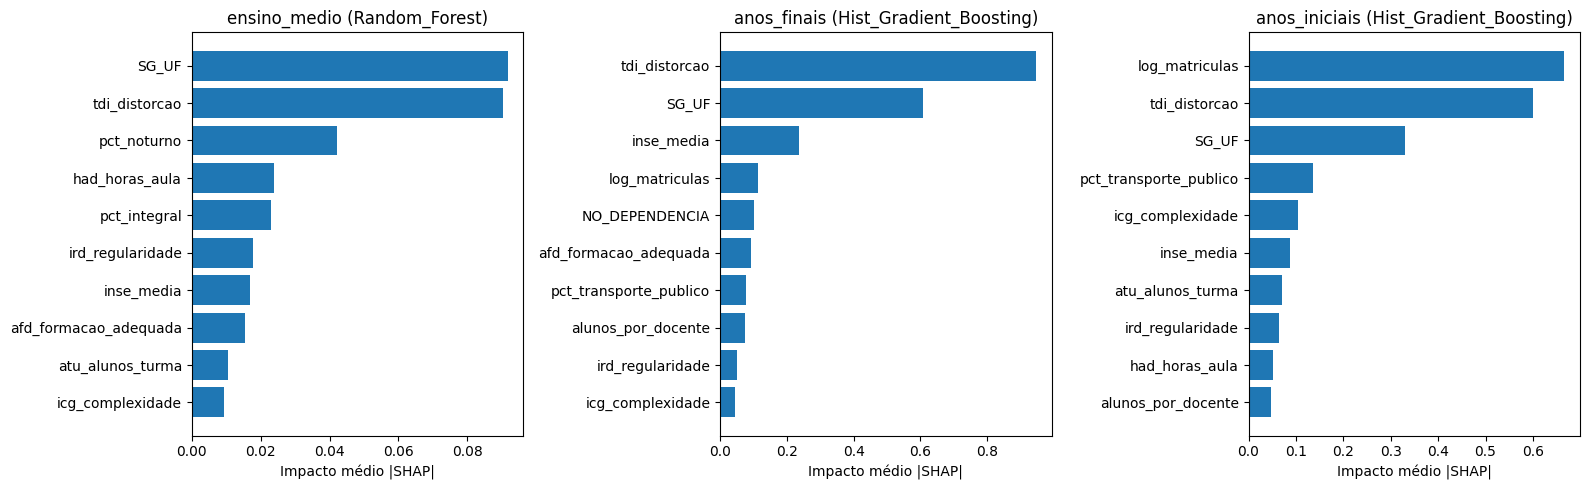

,etapa,variavel,importancia_media_abs,direcao
0,ensino_medio,SG_UF,0.0917,categórica (ver por categoria)
1,ensino_medio,tdi_distorcao,0.0904,maior valor → maior prob.
2,ensino_medio,pct_noturno,0.0421,maior valor → maior prob.
3,ensino_medio,had_horas_aula,0.0238,maior valor → menor prob.
4,ensino_medio,pct_integral,0.0230,maior valor → menor prob.
5,ensino_medio,ird_regularidade,0.0178,maior valor → menor prob.
6,ensino_medio,inse_media,0.0169,maior valor → menor prob.
7,ensino_medio,afd_formacao_adequada,0.0154,maior valor → menor prob.
20,anos_finais,tdi_distorcao,0.9464,maior valor → maior prob.
21,anos_finais,SG_UF,0.6089,categórica (ver por categoria)


In [9]:
import shap                                                       # biblioteca de explicação dos modelos

resumo_shap = []                                                  # tabela final: importância e direção por variável
fig, eixos = plt.subplots(1, 3, figsize=(16, 5))                  # 3 gráficos de barras, um por etapa

for i, etapa in enumerate(ETAPAS):
    sub, X, y = dados[etapa]
    amostra = X.sample(n=2000, random_state=SEED)                 # 2.000 escolas sorteadas (sempre as mesmas)

    prep = modelos[etapa].named_steps["prep"]                     # parte de tratamento do modelo final
    clf = modelos[etapa].named_steps["clf"]                       # parte do modelo em si
    nomes = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]   # "num__tdi_distorcao" → "tdi_distorcao"
    Xt = pd.DataFrame(prep.transform(amostra), columns=nomes)     # dados já tratados, do jeito que o modelo vê

    explicador = shap.TreeExplainer(clf)                          # explicador próprio para modelos de árvore
    valores = explicador.shap_values(Xt, check_additivity=False)  # contribuição de cada variável em cada escola
    if isinstance(valores, list):                                 # versões antigas devolvem uma lista por classe...
        valores = valores[1]                                      # ...pegamos a classe 1 (alto abandono)
    valores = np.asarray(valores)
    if valores.ndim == 3:                                         # Random Forest devolve [escola, variável, classe]...
        valores = valores[:, :, 1]                                # ...pegamos a classe 1

    # O OneHot transformou UF em 27 colunas (SG_UF_SP, SG_UF_AC...). Somamos de volta numa só.
    origem = {n: next((c for c in CAT_BASE if n.startswith(c + "_")), n) for n in nomes}   # coluna → variável original
    shap_df = pd.DataFrame(valores, columns=nomes)
    shap_agrup = shap_df.T.groupby(origem).sum().T                # soma as colunas de cada variável original

    importancia = shap_agrup.abs().mean().sort_values(ascending=False)   # média do impacto (sem sinal) = importância

    for var, imp in importancia.items():
        if var in NUM_BASE:                                       # numéricas: dá para calcular a direção
            rho = pd.Series(Xt[var]).corr(shap_df[var], method="spearman")   # valor alto → empurra para cima ou baixo?
            if pd.isna(rho):                                      # variável constante na amostra
                direcao = "sem variação na amostra"
            elif rho > 0:
                direcao = "maior valor → maior prob."
            else:
                direcao = "maior valor → menor prob."
        else:                                                     # categóricas (UF, urbana/rural, rede)
            direcao = "categórica (ver por categoria)"
        resumo_shap.append({"etapa": etapa, "variavel": var,
                            "importancia_media_abs": round(imp, 4), "direcao": direcao})

    top10 = importancia.head(10)[::-1]                            # 10 mais importantes (invertido para o gráfico)
    eixos[i].barh(top10.index, top10.values)
    eixos[i].set_title(f"{etapa} ({MELHOR_MODELO[etapa]})")
    eixos[i].set_xlabel("Impacto médio |SHAP|")

plt.tight_layout()
plt.savefig("resultados/sprint6/03_shap_importancia.png", dpi=300, bbox_inches="tight")
plt.show()

shap_tabela = pd.DataFrame(resumo_shap)
shap_tabela.to_csv("resultados/sprint6/03_shap_importancia.csv", index=False, encoding="utf-8-sig")
shap_tabela.groupby("etapa").head(8)                              # mostra as 8 principais de cada etapa

In [10]:
shap_tabela[shap_tabela["direcao"] == "sem variação na amostra"]   # mostra só as variáveis constantes

,etapa,variavel,importancia_media_abs,direcao
19,ensino_medio,flag_sem_turma_etapa,0.0,sem variação na amostra
39,anos_finais,flag_sem_turma_etapa,0.0,sem variação na amostra
59,anos_iniciais,pct_noturno,0.0,sem variação na amostra
